Upload the zip file to colab

In [3]:
from google.colab import files

uploaded = files.upload()

Saving Data set.zip to Data set.zip


Extract the dataset

In [4]:
import zipfile

with zipfile.ZipFile("Data set.zip", "r") as zip_ref:
    zip_ref.extractall("/Data_set")

Check that everything is there

In [5]:
import os

dataset_path = "/Data_set/Data set"

print(os.listdir(dataset_path))
print(os.listdir(dataset_path + "/Training"))
print(os.listdir(dataset_path + "/Testing"))

['Testing', 'Training']
['glioma', 'meningioma', 'pituitary', 'notumor']
['glioma', 'meningioma', 'pituitary', 'notumor']


In [6]:
print(os.getcwd())
print(os.listdir("/Data_set/Data set/Testing"))

/content
['glioma', 'meningioma', 'pituitary', 'notumor']


In [7]:
print(os.listdir("/Data_set/Data set/Training"))

['glioma', 'meningioma', 'pituitary', 'notumor']


**Data Preprocessing**

Step 1 — Check corrupted/unreadable images

In [8]:
from PIL import Image


dataset_path = "/Data_set/Data set"

classes = ["glioma", "meningioma", "pituitary", "notumor"]

def check_images(split):
    bad_images = []

    for cls in classes:
        folder = os.path.join(dataset_path, split, cls)

        for filename in os.listdir(folder):
            filepath = os.path.join(folder, filename)

            try:
                with Image.open(filepath) as img:
                    img.verify()
            except Exception:
                bad_images.append(filepath)

    return bad_images


bad_training = check_images("Training")
bad_testing = check_images("Testing")

print("Bad training images:", len(bad_training))
print("Bad testing images:", len(bad_testing))

Bad training images: 0
Bad testing images: 0


Step 2 : Checking the class distribution

In [9]:
classes = ["glioma", "meningioma", "pituitary", "notumor"]

for split in ["Training", "Testing"]:
    print(f"\n{split}")
    print("-" * 30)

    for cls in classes:
        folder = os.path.join(dataset_path, split, cls)
        count = len(os.listdir(folder))
        print(f"{cls}: {count}")


Training
------------------------------
glioma: 1400
meningioma: 1400
pituitary: 1400
notumor: 1400

Testing
------------------------------
glioma: 400
meningioma: 400
pituitary: 400
notumor: 400


# Before deciding on resizing, normalization, augmentation, or even the model input format, we should first characterize the raw images.

Image dimensions — e.g. 512×512, 300×400, etc.

Number of channels — RGB, grayscale, RGBA, etc.

Image formats — JPG, PNG, etc.

Pixel-value range

Aspect-ratio distribution

Class-wise image counts — already checked

Corrupted images — already checked

In [10]:
from PIL import Image
import os
from collections import Counter

dataset_path = "/Data_set/Data set"

classes = ["glioma", "meningioma", "pituitary", "notumor"]

def analyze_images(split):

    sizes = Counter()
    modes = Counter()
    formats = Counter()

    total_images = 0

    for cls in classes:

        folder = os.path.join(dataset_path, split, cls)

        for filename in os.listdir(folder):

            filepath = os.path.join(folder, filename)

            try:
                with Image.open(filepath) as img:

                    total_images += 1

                    # Image dimensions
                    sizes[img.size] += 1

                    # RGB, L (grayscale), RGBA, etc.
                    modes[img.mode] += 1

                    # JPG, PNG, etc.
                    formats[img.format] += 1

            except Exception:
                pass

    return total_images, sizes, modes, formats


for split in ["Training", "Testing"]:

    total, sizes, modes, formats = analyze_images(split)

    print("\n" + "=" * 50)
    print(split)
    print("=" * 50)

    print("Total images:", total)

    print("\nImage modes:")
    for mode, count in modes.items():
        print(f"{mode}: {count}")

    print("\nImage formats:")
    for fmt, count in formats.items():
        print(f"{fmt}: {count}")

    print("\nNumber of unique image sizes:", len(sizes))

    print("\nMost common image sizes:")
    for size, count in sizes.most_common(10):
        print(f"{size}: {count}")


Training
Total images: 5600

Image modes:
L: 2358
RGB: 3238
RGBA: 3
P: 1

Image formats:
JPEG: 5596
PNG: 4

Number of unique image sizes: 381

Most common image sizes:
(512, 512): 4012
(225, 225): 253
(630, 630): 69
(201, 251): 40
(236, 236): 39
(442, 442): 38
(150, 198): 33
(228, 221): 32
(232, 217): 32
(428, 417): 31

Testing
Total images: 1600

Image modes:
RGB: 891
L: 709

Image formats:
JPEG: 1600

Number of unique image sizes: 203

Most common image sizes:
(512, 512): 1002
(225, 225): 85
(630, 630): 21
(228, 221): 19
(227, 222): 19
(232, 217): 18
(201, 251): 17
(200, 252): 14
(300, 168): 13
(256, 256): 11


Before resizing images in to the same dimensions we want to look in to the aspect ratio

In [11]:
from PIL import Image
import os
import numpy as np

dataset_path = "/Data_set/Data set"

classes = [
    "glioma",
    "meningioma",
    "pituitary",
    "notumor"
]

def get_aspect_ratios(split):

    aspect_ratios = []

    for cls in classes:

        folder = os.path.join(dataset_path, split, cls)

        for filename in os.listdir(folder):

            filepath = os.path.join(folder, filename)

            try:
                with Image.open(filepath) as img:

                    width, height = img.size

                    aspect_ratio = width / height

                    aspect_ratios.append(aspect_ratio)

            except Exception:
                pass

    return aspect_ratios


for split in ["Training", "Testing"]:

    ratios = get_aspect_ratios(split)

    print("\n" + "=" * 50)
    print(split)
    print("=" * 50)

    print("Number of images:", len(ratios))
    print("Minimum:", min(ratios))
    print("Maximum:", max(ratios))
    print("Mean:", np.mean(ratios))
    print("Median:", np.median(ratios))
    print("Std:", np.std(ratios))


Training
Number of images: 5600
Minimum: 0.644808743169399
Maximum: 1.7857142857142858
Mean: 0.9884351556534875
Median: 1.0
Std: 0.0792933013040153

Testing
Number of images: 1600
Minimum: 0.7169811320754716
Maximum: 1.7857142857142858
Mean: 0.9941241920027886
Median: 1.0
Std: 0.1256382671439496


In the training dataset the mean is 0.9884 and the median is 1.0 and in the testing dataset the mean is 0.994 and the median is 1.0 so i think the existing aspect ratios are good

Croping the image dataset

In [12]:
!pip install imutils

import cv2
import numpy as np
import imutils
from PIL import Image


def crop_img(img):
    """
    Remove unnecessary background/margins from a brain MRI.

    Based on the preprocessing method provided by the
    dataset author.
    """

    # OpenCV loads images as BGR
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # Smooth the image
    gray = cv2.GaussianBlur(gray, (3, 3), 0)

    # Threshold
    thresh = cv2.threshold(
        gray,
        45,
        255,
        cv2.THRESH_BINARY
    )[1]

    # Remove small noise
    thresh = cv2.erode(
        thresh,
        None,
        iterations=2
    )

    thresh = cv2.dilate(
        thresh,
        None,
        iterations=2
    )

    # Find external contours
    cnts = cv2.findContours(
        thresh.copy(),
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )

    cnts = imutils.grab_contours(cnts)

    # If no contour is found, return original image
    if len(cnts) == 0:
        return img.copy()

    # Largest contour
    c = max(cnts, key=cv2.contourArea)

    # Extreme points
    extLeft = tuple(c[c[:, :, 0].argmin()][0])
    extRight = tuple(c[c[:, :, 0].argmax()][0])
    extTop = tuple(c[c[:, :, 1].argmin()][0])
    extBot = tuple(c[c[:, :, 1].argmax()][0])

    # No additional pixels, same as author's ADD_PIXELS = 0
    ADD_PIXELS = 0

    # Image dimensions
    h, w = img.shape[:2]

    # Make sure crop coordinates stay inside image
    x1 = max(extLeft[0] - ADD_PIXELS, 0)
    x2 = min(extRight[0] + ADD_PIXELS, w)

    y1 = max(extTop[1] - ADD_PIXELS, 0)
    y2 = min(extBot[1] + ADD_PIXELS, h)

    # Crop
    new_img = img[y1:y2, x1:x2].copy()

    return new_img

Test croping

In [13]:
import os

folder = "/Data_set/Data set/Training/glioma"

files = os.listdir(folder)

print(files[:10])

['Tr-gl_838.jpg', 'Tr-gl_225.jpg', 'Tr-gl_258.jpg', 'Tr-gl_161.jpg', 'Tr-gl_240.jpg', 'Tr-gl_653.jpg', 'Tr-gl_1007.jpg', 'Tr-gl_905.jpg', 'Tr-gl_1006.jpg', 'Tr-gl_127.jpg']


In [37]:
import os
import cv2
from tqdm import tqdm

# Original dataset
dataset_path = "/Data_set/Data set"

# New dataset for cropped images
cropped_path = "/Data_set/Cropped"

classes = [
    "glioma",
    "meningioma",
    "pituitary",
    "notumor"
]

splits = [
    "Training",
    "Testing"
]


for split in splits:

    for cls in classes:

        # Input folder
        input_folder = os.path.join(
            dataset_path,
            split,
            cls
        )

        # Output folder
        output_folder = os.path.join(
            cropped_path,
            split,
            cls
        )

        # Create output folder
        os.makedirs(
            output_folder,
            exist_ok=True
        )

        # Get all files
        files = os.listdir(input_folder)

        print(f"\nProcessing {split}/{cls}")
        print("Images:", len(files))

        # Process every image
        for filename in tqdm(files):

            input_path = os.path.join(
                input_folder,
                filename
            )

            output_path = os.path.join(
                output_folder,
                filename
            )

            # Read image
            image = cv2.imread(input_path)

            # Check if image was readable
            if image is None:
                print("Could not read:", input_path)
                continue

            # Crop margins
            cropped = crop_img(image)

            # Save cropped image
            cv2.imwrite(
                output_path,
                cropped
            )

print("\nCropping completed!")


Processing Training/glioma
Images: 1400


100%|██████████| 1400/1400 [00:10<00:00, 139.02it/s]



Processing Training/meningioma
Images: 1400


100%|██████████| 1400/1400 [00:13<00:00, 104.61it/s]



Processing Training/pituitary
Images: 1400


100%|██████████| 1400/1400 [00:13<00:00, 104.70it/s]


... (7 outputs left out)

100%|██████████| 400/400 [00:03<00:00, 125.89it/s]



Processing Testing/notumor
Images: 400


100%|██████████| 400/400 [00:01<00:00, 311.26it/s]


Cropping completed!


Display original vs cropped

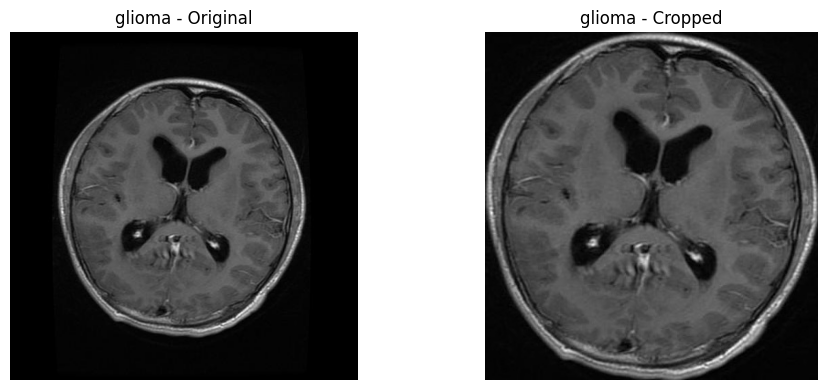

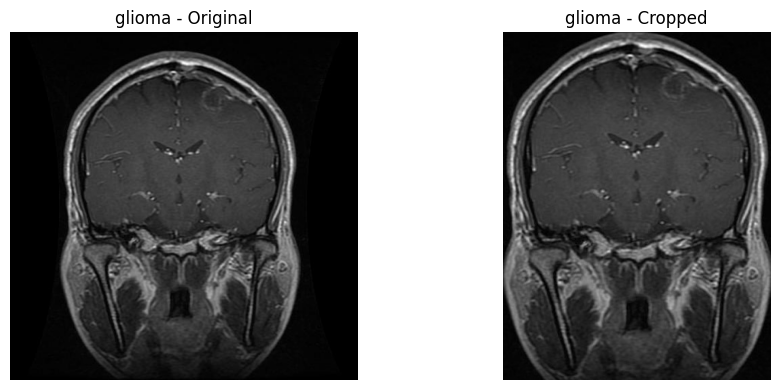

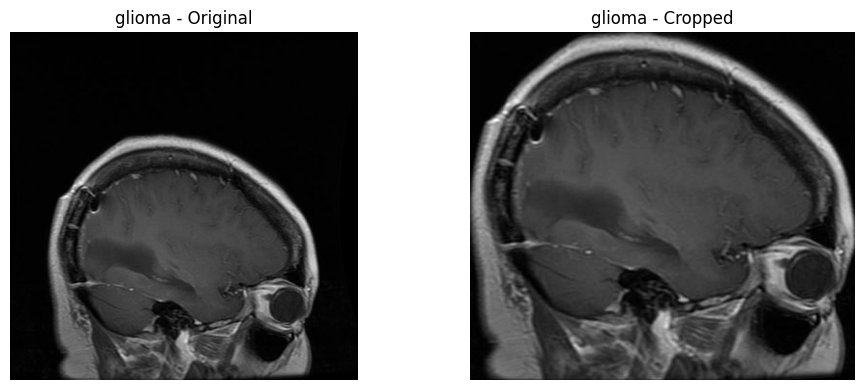

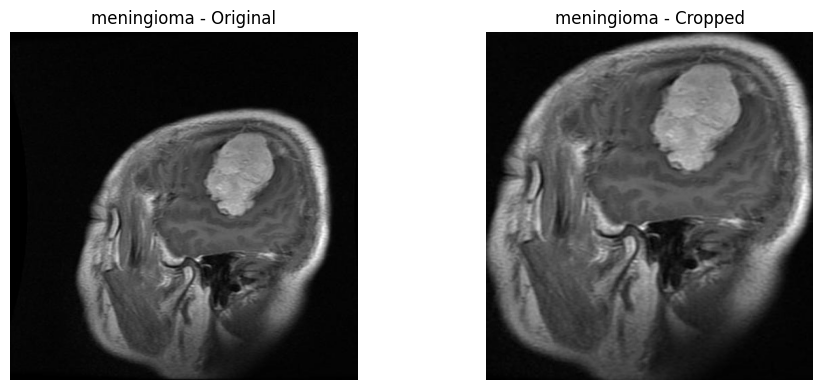

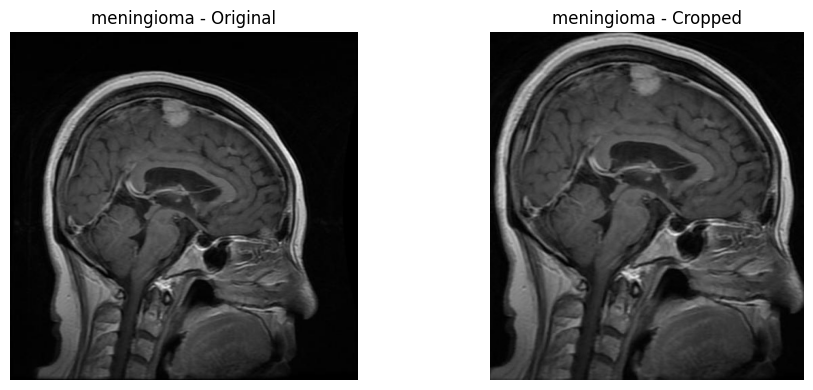

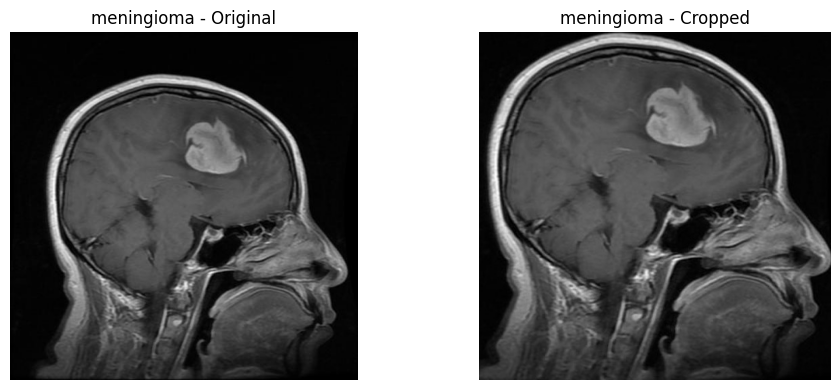

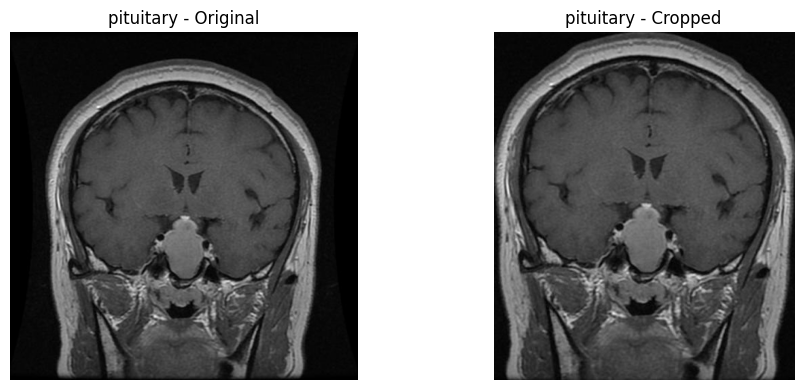

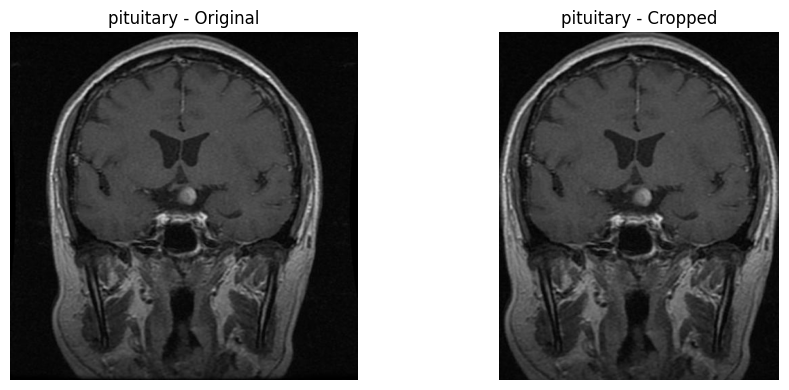

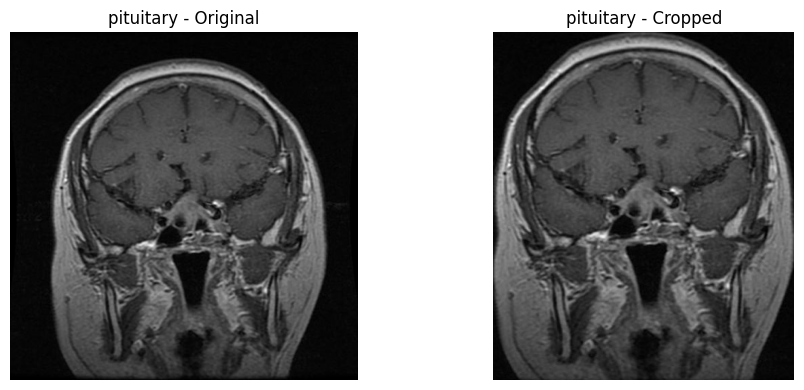

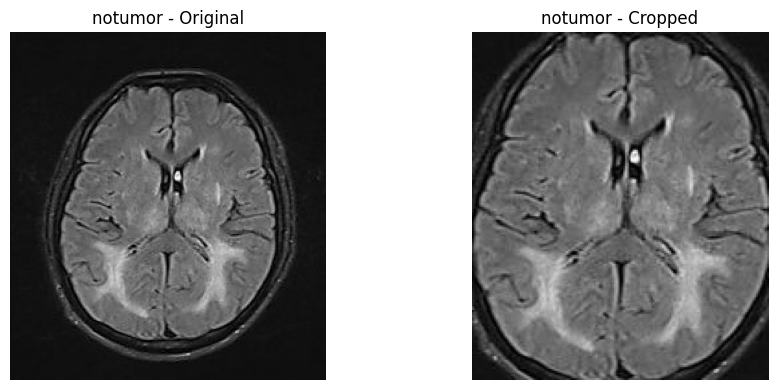

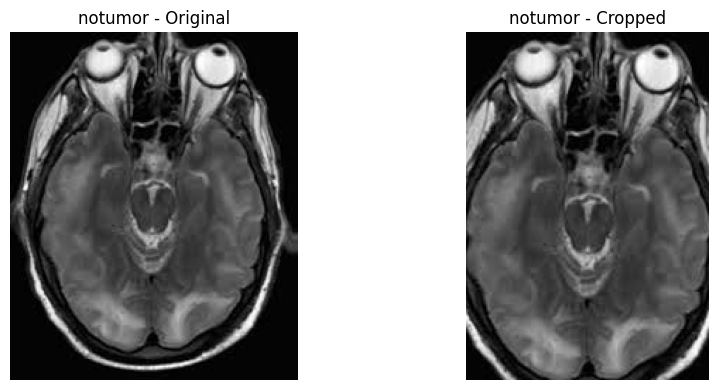

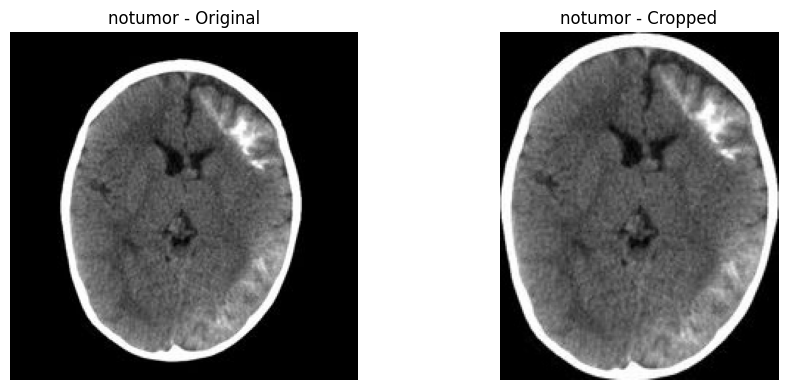

In [38]:
import os
import cv2
import matplotlib.pyplot as plt
import random

original_path = "/Data_set/Data set"
cropped_path = "/Data_set/Cropped"

classes = [
    "glioma",
    "meningioma",
    "pituitary",
    "notumor"
]

split = "Training"

# Number of examples per class
num_examples = 3

for cls in classes:

    original_folder = os.path.join(
        original_path,
        split,
        cls
    )

    cropped_folder = os.path.join(
        cropped_path,
        split,
        cls
    )

    # Get original images
    files = [
        f for f in os.listdir(original_folder)
        if os.path.isfile(os.path.join(original_folder, f))
    ]

    # Randomly select images
    selected_files = random.sample(
        files,
        min(num_examples, len(files))
    )

    for filename in selected_files:

        original_file = os.path.join(
            original_folder,
            filename
        )

        cropped_file = os.path.join(
            cropped_folder,
            filename
        )

        # Read images
        original = cv2.imread(original_file)
        cropped = cv2.imread(cropped_file)

        # Convert BGR → RGB
        original = cv2.cvtColor(
            original,
            cv2.COLOR_BGR2RGB
        )

        cropped = cv2.cvtColor(
            cropped,
            cv2.COLOR_BGR2RGB
        )

        # Display
        plt.figure(figsize=(10, 4))

        plt.subplot(1, 2, 1)
        plt.imshow(original)
        plt.title(f"{cls} - Original")
        plt.axis("off")

        plt.subplot(1, 2, 2)
        plt.imshow(cropped)
        plt.title(f"{cls} - Cropped")
        plt.axis("off")

        plt.tight_layout()
        plt.show()

Analyze the cropped images

In [39]:
from PIL import Image
import os
import numpy as np

cropped_path = "/Data_set/Cropped"

classes = [
    "glioma",
    "meningioma",
    "pituitary",
    "notumor"
]


def analyze_cropped_images(split):

    aspect_ratios = []
    widths = []
    heights = []

    for cls in classes:

        folder = os.path.join(
            cropped_path,
            split,
            cls
        )

        for filename in os.listdir(folder):

            filepath = os.path.join(
                folder,
                filename
            )

            try:
                with Image.open(filepath) as img:

                    width, height = img.size

                    widths.append(width)
                    heights.append(height)

                    aspect_ratios.append(
                        width / height
                    )

            except Exception:
                pass

    return (
        widths,
        heights,
        aspect_ratios
    )


for split in ["Training", "Testing"]:

    widths, heights, ratios = analyze_cropped_images(split)

    print("\n" + "=" * 50)
    print(split)
    print("=" * 50)

    print("Number of images:", len(ratios))

    print("Minimum width:", min(widths))
    print("Maximum width:", max(widths))

    print("Minimum height:", min(heights))
    print("Maximum height:", max(heights))

    print("Mean aspect ratio:", np.mean(ratios))
    print("Median aspect ratio:", np.median(ratios))
    print("Standard deviation:", np.std(ratios))

    print("Minimum aspect ratio:", min(ratios))
    print("Maximum aspect ratio:", max(ratios))


Training
Number of images: 5600
Minimum width: 36
Maximum width: 1364
Minimum height: 44
Maximum height: 1413
Mean aspect ratio: 0.8746602788807613
Median aspect ratio: 0.8589108910891089
Standard deviation: 0.12875400785172555
Minimum aspect ratio: 0.22272727272727272
Maximum aspect ratio: 2.4545454545454546

Testing
Number of images: 1600
Minimum width: 36
Maximum width: 724
Minimum height: 44
Maximum height: 708
Mean aspect ratio: 0.8831904069176789
Median aspect ratio: 0.8639892751220779
Standard deviation: 0.13028776474842402
Minimum aspect ratio: 0.5929203539823009
Maximum aspect ratio: 2.4545454545454546


I think aspect ratios are also good

Now we are going to split the dataset

In [40]:
import os
import shutil
from sklearn.model_selection import train_test_split
from tqdm import tqdm

# Cropped dataset
dataset_path = "/Data_set/Cropped"

# Classes
classes = [
    "glioma",
    "meningioma",
    "pituitary",
    "notumor"
]

# Random seed for reproducibility
RANDOM_STATE = 42

# Split ratio
VALIDATION_SIZE = 0.20


for cls in classes:

    # Original cropped training folder
    source_folder = os.path.join(
        dataset_path,
        "Training",
        cls
    )

    # Get image filenames
    files = [
        f for f in os.listdir(source_folder)
        if os.path.isfile(
            os.path.join(source_folder, f)
        )
    ]

    # Split into train and validation
    train_files, val_files = train_test_split(
        files,
        test_size=VALIDATION_SIZE,
        random_state=RANDOM_STATE
    )

    # Create destination folders
    train_folder = os.path.join(
        dataset_path,
        "Train",
        cls
    )

    val_folder = os.path.join(
        dataset_path,
        "Validation",
        cls
    )

    os.makedirs(
        train_folder,
        exist_ok=True
    )

    os.makedirs(
        val_folder,
        exist_ok=True
    )

    # Copy training images
    for filename in tqdm(
        train_files,
        desc=f"Train - {cls}"
    ):

        source = os.path.join(
            source_folder,
            filename
        )

        destination = os.path.join(
            train_folder,
            filename
        )

        shutil.copy2(source, destination)

    # Copy validation images
    for filename in tqdm(
        val_files,
        desc=f"Validation - {cls}"
    ):

        source = os.path.join(
            source_folder,
            filename
        )

        destination = os.path.join(
            val_folder,
            filename
        )

        shutil.copy2(source, destination)


print("\nDataset splitting completed!")

Validation - notumor: 100%|██████████| 280/280 [00:00<00:00, 5439.50it/s]


Dataset splitting completed!


Verify the split

In [41]:
for split in ["Train", "Validation", "Testing"]:

    print("\n" + "=" * 40)
    print(split)
    print("=" * 40)

    for cls in classes:

        folder = os.path.join(
            dataset_path,
            split,
            cls
        )

        count = len([
            f for f in os.listdir(folder)
            if os.path.isfile(
                os.path.join(folder, f)
            )
        ])

        print(f"{cls}: {count}")


Train
glioma: 1120
meningioma: 1120
pituitary: 1120
notumor: 1120

Validation
glioma: 280
meningioma: 280
pituitary: 280
notumor: 280

Testing
glioma: 400
meningioma: 400
pituitary: 400
notumor: 400


Now we are going to resize all images and convert all images in to a RGB

In [51]:
import tensorflow as tf

dataset_path = "/Data_set/Cropped"

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

train_ds = tf.keras.utils.image_dataset_from_directory(
    f"{dataset_path}/Train",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="categorical",
    shuffle=True,
    seed=SEED
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    f"{dataset_path}/Validation",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="categorical",
    shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    f"{dataset_path}/Testing",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="categorical",
    shuffle=False
)

# --------------------------------
# Data Augmentation
# --------------------------------

data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomRotation(0.05),
    tf.keras.layers.RandomZoom(0.10),
    tf.keras.layers.RandomTranslation(
        height_factor=0.05,
        width_factor=0.05
    ),
], name="data_augmentation")

Found 4480 files belonging to 4 classes.
Found 1120 files belonging to 4 classes.
Found 1600 files belonging to 4 classes.


Before adding normalization and augmentation, let's make sure Keras is loading them correctly.

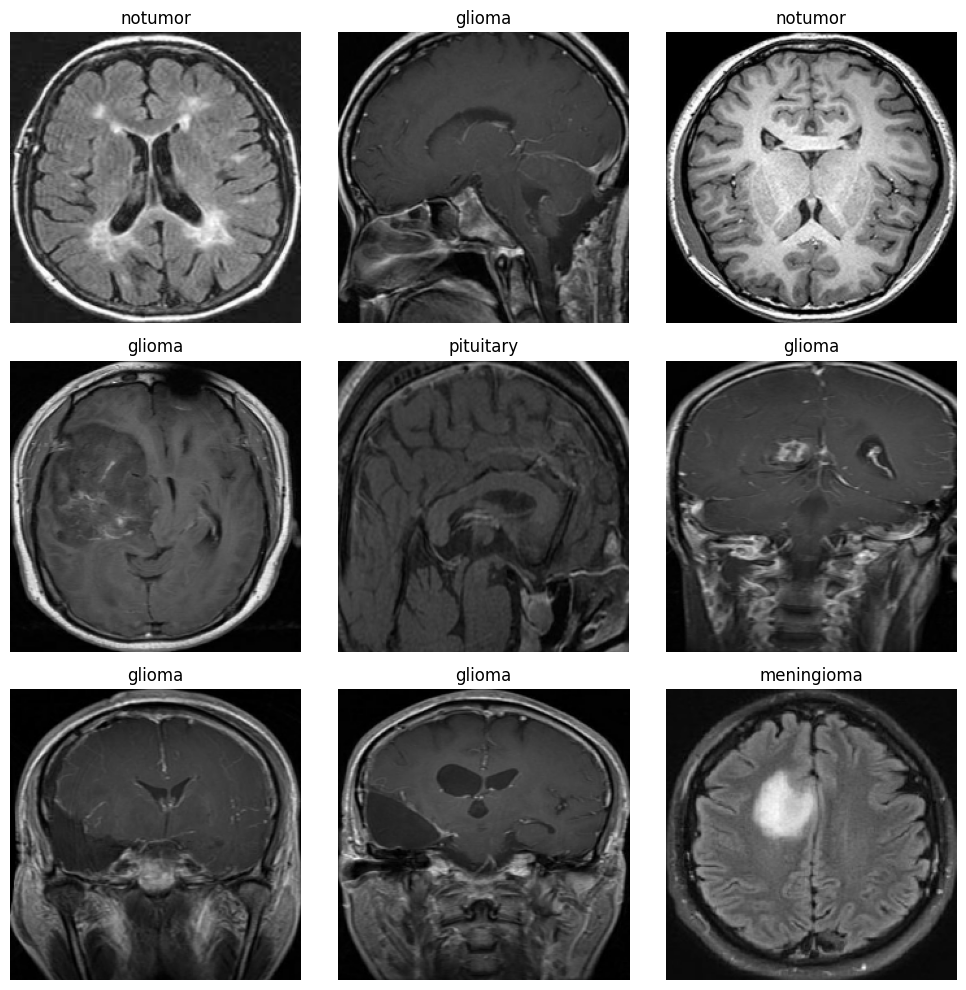

In [56]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 10))

for images, labels in train_ds.take(1):

    for i in range(9):

        ax = plt.subplot(3, 3, i + 1)

        plt.imshow(images[i].numpy().astype("uint8"))

        class_index = tf.argmax(labels[i]).numpy()

        plt.title(train_ds.class_names[class_index])

        plt.axis("off")

plt.tight_layout()
plt.show()

In [53]:
for images, labels in train_ds.take(1):
    print("Image shape:", images.shape)
    print("Label shape:", labels.shape)

Image shape: (32, 224, 224, 3)
Label shape: (32, 4)


In [54]:
print(train_ds.class_names)

['glioma', 'meningioma', 'notumor', 'pituitary']


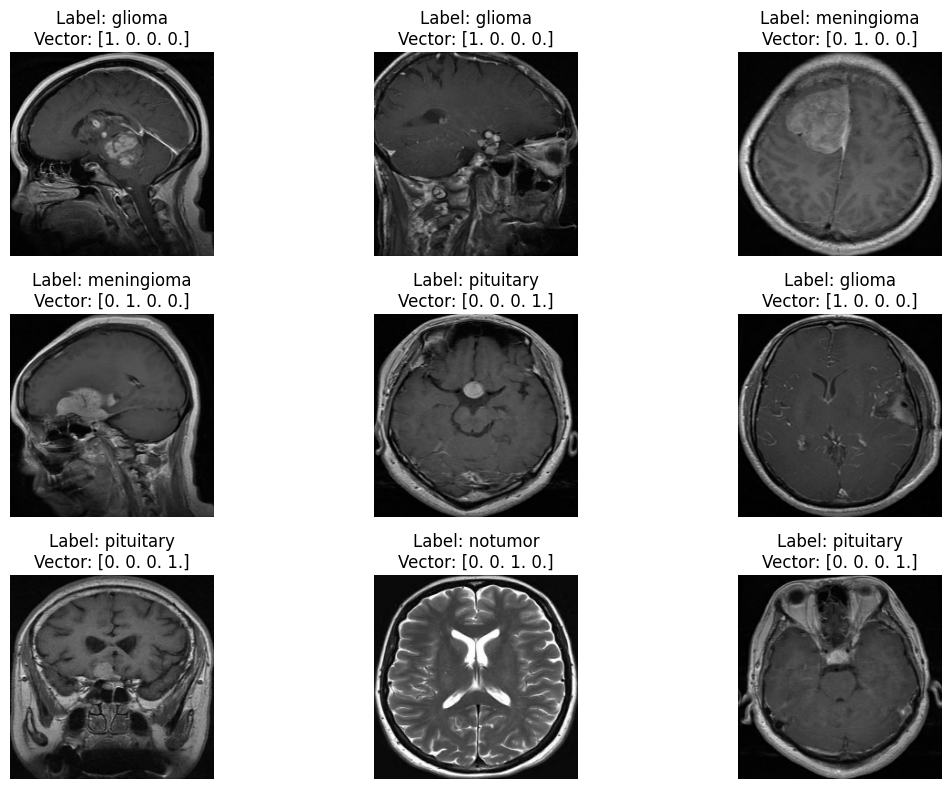

In [55]:
import matplotlib.pyplot as plt
import tensorflow as tf

class_names = train_ds.class_names

for images, labels in train_ds.take(1):

    plt.figure(figsize=(12, 8))

    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)

        plt.imshow(images[i].numpy().astype("uint8"))

        label_index = tf.argmax(labels[i]).numpy()
        label_name = class_names[label_index]

        plt.title(
            f"Label: {label_name}\n"
            f"Vector: {labels[i].numpy()}"
        )

        plt.axis("off")

    plt.tight_layout()
    plt.show()